# Lab - EDA Bivariado: Amazon UK Product Insights Part II

## Objetivo de negocio

El objetivo de este análisis es estudiar las relaciones entre categorías, precios, ratings y estado de best-seller dentro del dataset de productos de Amazon UK.

Este análisis puede ayudar a responder preguntas como:

- ¿Qué categorías tienen mayor proporción de productos best-seller?
- ¿Existe relación entre la categoría del producto y ser best-seller?
- ¿Qué categorías tienden a tener precios más altos?
- ¿Qué categorías reciben mejores valoraciones?
- ¿Existe relación entre el precio y el rating de los productos?

In [1]:
# Importar librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency
from scipy import stats

In [2]:
# Cargar dataset
df = pd.read_csv("/Users/gabrielbohorquez/Desktop/Ironhack/Semana_5/Dia_2_12_Mayo/lab-eda-bivariate/amz_uk_price_prediction_dataset.csv")

df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [3]:
# revisar estructura:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [4]:
# limpiar nombres de columnas
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isbestseller',
       'boughtinlastmonth', 'category'],
      dtype='object')

In [5]:
# revisar primeras filas
df.head()

,uid,asin,title,stars,reviews,price,isbestseller,boughtinlastmonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [7]:
# definir columnas principales
category_col = "category"
price_col = "price"
rating_col = "stars"
bestseller_col = "isbestseller"

df[[category_col, price_col, rating_col, bestseller_col]].head()

,category,price,stars,isbestseller
0,Hi-Fi Speakers,21.99,4.7,False
1,Hi-Fi Speakers,23.99,4.7,True
2,Hi-Fi Speakers,21.99,4.7,False
3,Hi-Fi Speakers,31.99,4.7,False
4,Hi-Fi Speakers,17.99,4.6,False


In [8]:
# limpiar precio y rating
df[price_col] = (
    df[price_col]
    .astype(str)
    .str.replace("£", "", regex=False)
    .str.replace(",", "", regex=False)
)

df[price_col] = pd.to_numeric(df[price_col], errors="coerce")
df[rating_col] = pd.to_numeric(df[rating_col], errors="coerce")

df[[price_col, rating_col]].describe()

,price,stars
count,2.443651e+06,2.443651e+06
mean,8.924381e+01,2.152836e+00
std,3.456089e+02,2.194865e+00
min,0.000000e+00,0.000000e+00
25%,9.990000e+00,0.000000e+00
50%,1.909000e+01,0.000000e+00
75%,4.599000e+01,4.400000e+00
max,1.000000e+05,5.000000e+00


In [9]:
# revisar valores nulos
df[[category_col, price_col, rating_col, bestseller_col]].isna().sum()

category        0
price           0
stars           0
isbestseller    0
dtype: int64

# Parte 1: Tendencias de best-seller por categoría

## Pregunta de negocio

¿Existen categorías de producto donde ser best-seller sea más frecuente?

En esta sección analizaremos la relación entre la categoría del producto y la variable `isBestSeller`.

In [10]:
# revisar valores de isBestSeller
df[bestseller_col].value_counts(dropna=False)

isbestseller
False    2435671
True        7980
Name: count, dtype: int64

In [11]:
# crosstab entre categoría y best-seller
category_bestseller_crosstab = pd.crosstab(
    df[category_col],
    df[bestseller_col]
)

category_bestseller_crosstab

isbestseller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


## Interpretación de la tabla cruzada (crosstab)

La tabla cruzada muestra cuántos productos son best-seller y cuántos no lo son dentro de cada categoría.

Esto permite comparar la presencia de productos best-seller entre categorías, pero todavía no muestra proporciones. Para eso calcularemos el porcentaje de best-sellers por categoría.

In [12]:
# proporción de best-sellers por categoría
bestseller_proportion = pd.crosstab(
    df[category_col],
    df[bestseller_col],
    normalize="index"
)

bestseller_proportion.head()

isbestseller,False,True
category,,
3D Printers,0.995968,0.004032
3D Printing & Scanning,0.999508,0.000492
Abrasive & Finishing Products,0.980000,0.020000
Action Cameras,0.999411,0.000589
Adapters,0.988189,0.011811


In [14]:
# ordenar categorías por proporción de best-sellers
# Primero miramos las columnas para saber cuál es la de best-sellers (True o False)
bestseller_proportion.columns

Index([False, True], dtype='bool', name='isbestseller')

In [15]:
positive_bestseller_value = True

if True in bestseller_proportion.columns:
    positive_bestseller_value = True
elif 1 in bestseller_proportion.columns:
    positive_bestseller_value = 1
elif "True" in bestseller_proportion.columns:
    positive_bestseller_value = "True"
elif "Yes" in bestseller_proportion.columns:
    positive_bestseller_value = "Yes"

top_bestseller_categories = (
    bestseller_proportion[positive_bestseller_value]
    .sort_values(ascending=False)
)

top_bestseller_categories.head(10)

category
Grocery                           0.058135
Smart Home Security & Lighting    0.057692
Health & Personal Care            0.057686
Mobile Phone Accessories          0.042471
Power & Hand Tools                0.035339
Billiard, Snooker & Pool          0.032129
Pet Supplies                      0.030200
Home Brewing & Wine Making        0.028455
Wind Instruments                  0.028000
Mirrors                           0.028000
Name: True, dtype: float64

## Interpretación de proporciones

La proporción de best-sellers permite comparar categorías de forma más justa.

Una categoría puede tener muchos best-sellers en número absoluto simplemente porque tiene muchos productos publicados.

Por eso es mejor calcular qué porcentaje de productos dentro de cada categoría son best-sellers.

In [16]:
# Chi-square test
chi2, p_value, dof, expected = chi2_contingency(category_bestseller_crosstab)

print(f"Chi-square statistic: {chi2:.4f}")
print(f"P-value: {p_value:.4f}")
print(f"Degrees of freedom: {dof}")

Chi-square statistic: 36540.2027
P-value: 0.0000
Degrees of freedom: 295


## Interpretación del test Chi-square

El test Chi-square permite comprobar si existe una relación estadística entre dos variables categóricas:

- categoría del producto,
- estado de best-seller.

Hipótesis nula:

La categoría del producto y el estado de best-seller son independientes.

Hipótesis alternativa:

La categoría del producto y el estado de best-seller no son independientes.

Si el p-value es menor que 0.05, rechazamos la hipótesis nula y concluimos que existe una relación estadísticamente significativa entre la categoría y ser best-seller.

In [17]:
# Cramér's V
n = category_bestseller_crosstab.sum().sum()
rows, cols = category_bestseller_crosstab.shape

cramers_v = np.sqrt(
    chi2 / (n * (min(rows - 1, cols - 1)))
)

print(f"Cramér's V: {cramers_v:.4f}")

Cramér's V: 0.1223


## Interpretación de Cramér's V

Cramér's V mide la fuerza de asociación entre dos variables categóricas.

Su valor va de 0 a 1:

- cercano a 0: relación débil o casi inexistente,
- cercano a 1: relación fuerte.

Aunque el test Chi-square indique que hay relación estadística, Cramér's V nos ayuda a saber si esa relación es realmente fuerte desde un punto de vista práctico.

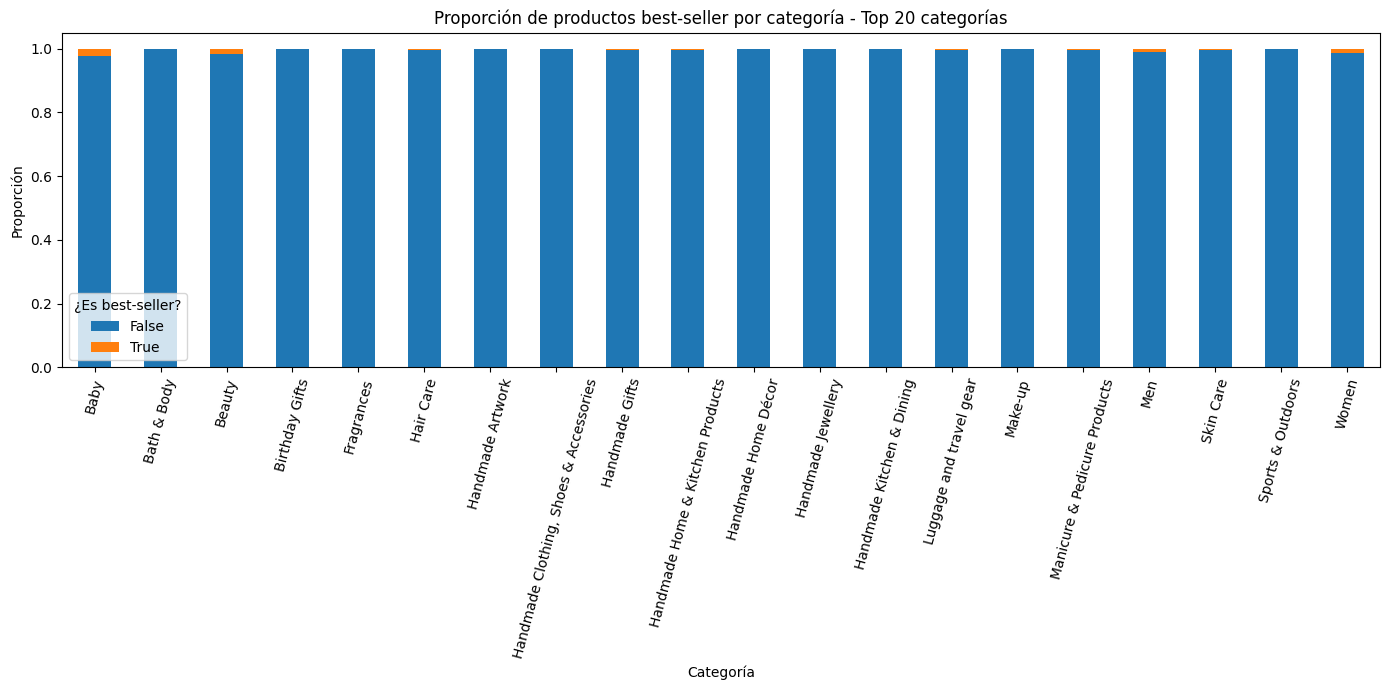

In [18]:
# stacked bar chart
top_20_categories = df[category_col].value_counts().head(20).index

df_top_20 = df[df[category_col].isin(top_20_categories)]

stacked_data = pd.crosstab(
    df_top_20[category_col],
    df_top_20[bestseller_col],
    normalize="index"
)

stacked_data.plot(
    kind="bar",
    stacked=True,
    figsize=(14, 7)
)

plt.title("Proporción de productos best-seller por categoría - Top 20 categorías")
plt.xlabel("Categoría")
plt.ylabel("Proporción")
plt.xticks(rotation=75)
plt.legend(title="¿Es best-seller?")
plt.tight_layout()
plt.show()

## Conclusión de negocio - Best-sellers por categoría

El análisis permite identificar qué categorías tienen mayor proporción de productos best-seller.

Desde una perspectiva de negocio, esto es útil porque una categoría con alta proporción de best-sellers puede indicar:

- mayor demanda,
- mejor conversión,
- mayor concentración de productos exitosos,
- oportunidad para estudiar qué características tienen esos productos.

Sin embargo, también es importante considerar el tamaño de cada categoría. Una categoría pequeña puede tener una proporción alta de best-sellers, pero pocos productos en total.

# Parte 2: Análisis de precios y ratings por categoría

## Paso preliminar: eliminación de outliers de precio

Antes de analizar los precios por categoría, eliminaremos outliers usando el método IQR.

Esto permite evitar que productos extremadamente caros distorsionen las visualizaciones y las medidas promedio.

In [19]:
# calcular límites IQR
q1 = df[price_col].quantile(0.25)
q3 = df[price_col].quantile(0.75)

iqr = q3 - q1

lower_limit = q1 - 1.5 * iqr
upper_limit = q3 + 1.5 * iqr

print(f"Q1: {q1:.2f}")
print(f"Q3: {q3:.2f}")
print(f"IQR: {iqr:.2f}")
print(f"Límite inferior: {lower_limit:.2f}")
print(f"Límite superior: {upper_limit:.2f}")

Q1: 9.99
Q3: 45.99
IQR: 36.00
Límite inferior: -44.01
Límite superior: 99.99


In [20]:
# crear dataframe sin outliers de precio
df_no_outliers = df[
    (df[price_col] >= lower_limit) &
    (df[price_col] <= upper_limit)
].copy()

print(f"Filas originales: {df.shape[0]}")
print(f"Filas sin outliers: {df_no_outliers.shape[0]}")
print(f"Filas eliminadas: {df.shape[0] - df_no_outliers.shape[0]}")

Filas originales: 2443651
Filas sin outliers: 2115963
Filas eliminadas: 327688


## Interpretación de eliminación de outliers

Se ha creado un nuevo dataframe llamado `df_no_outliers`, donde se eliminaron productos con precios extremadamente bajos o altos según el método IQR.

El objetivo no es borrar datos definitivamente, sino crear una versión más estable del dataset para analizar precios sin que los valores extremos distorsionen las visualizaciones.

## Violin Plot: distribución de precios por categoría

In [21]:
# top 20 categorías por cantidad
top_20_categories_no_outliers = (
    df_no_outliers[category_col]
    .value_counts()
    .head(20)
    .index
)

df_top_20_no_outliers = df_no_outliers[
    df_no_outliers[category_col].isin(top_20_categories_no_outliers)
]

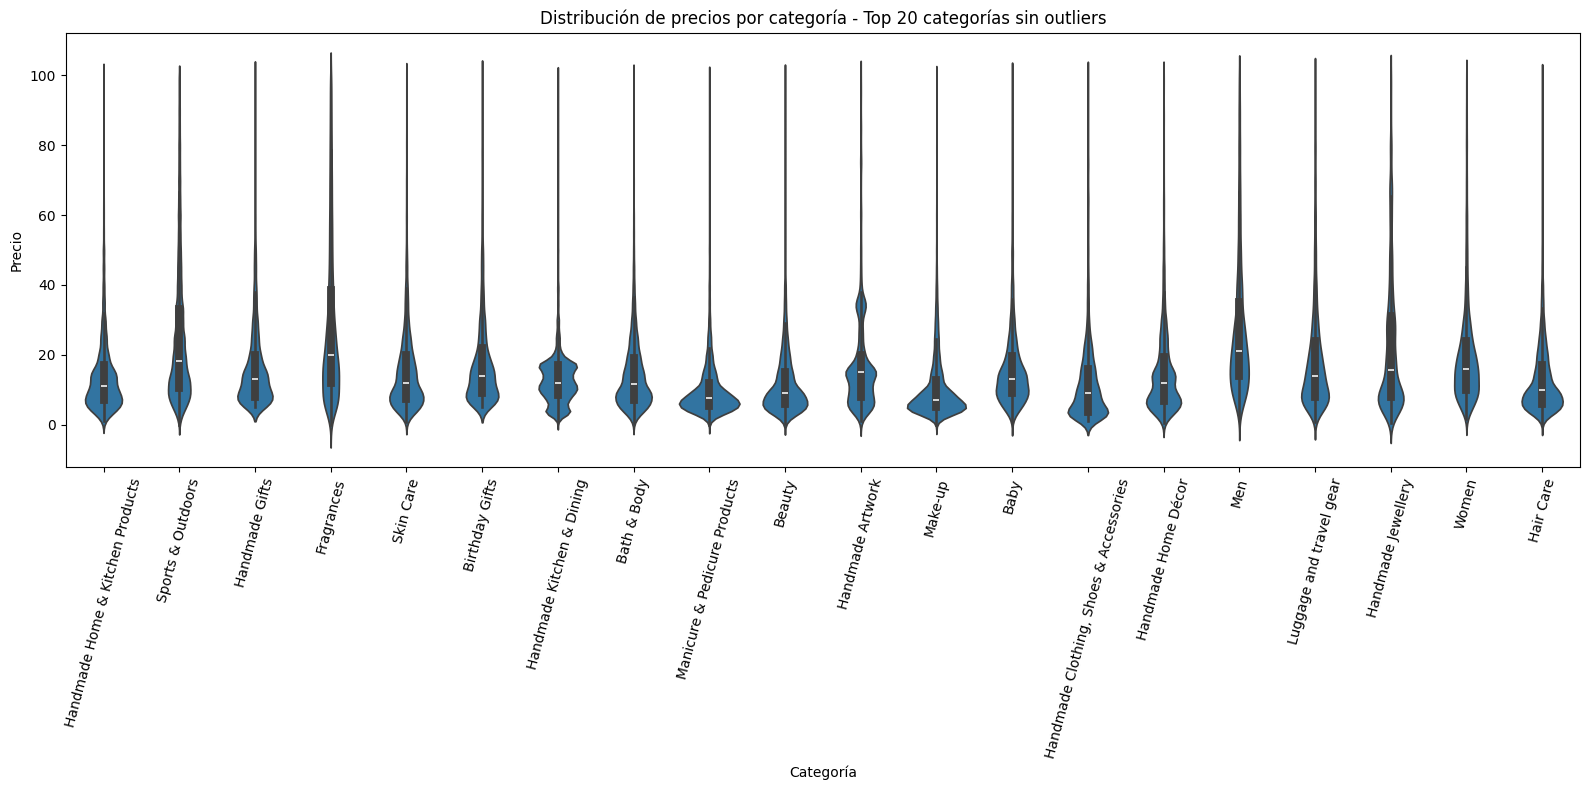

In [22]:
# violin plot
plt.figure(figsize=(16, 8))

sns.violinplot(
    data=df_top_20_no_outliers,
    x=category_col,
    y=price_col
)

plt.title("Distribución de precios por categoría - Top 20 categorías sin outliers")
plt.xlabel("Categoría")
plt.ylabel("Precio")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

## Interpretación del violin plot

El violin plot muestra cómo se distribuyen los precios dentro de cada categoría.

Permite observar:

- concentración de precios,
- dispersión,
- forma de la distribución,
- diferencias entre categorías.

Una categoría con un violín más ancho en ciertos rangos indica que muchos productos se concentran en esos precios.

## ¿Qué categoría tiene la mediana de precio más alta?

In [23]:
median_price_by_category = (
    df_no_outliers
    .groupby(category_col)[price_col]
    .median()
    .sort_values(ascending=False)
)

median_price_by_category.head(10)

category
Desktop PCs               74.00
Boxing Shoes              69.79
Tablets                   69.00
Graphics Cards            68.54
Motherboards              67.92
Made in Italy Handmade    64.00
Digital Frames            63.90
Streaming Clients         62.68
Golf Shoes                62.39
Ski Helmets               61.33
Name: price, dtype: float64

## Categoría con mayor mediana de precio

La categoría con mayor mediana de precio es la primera que aparece en la tabla ordenada de mayor a menor.

La mediana es una medida más robusta que la media porque no se ve tan afectada por valores extremos.

## Bar Chart: precio promedio por categoría

In [24]:
# top 10 categorías por cantidad
top_10_categories_no_outliers = (
    df_no_outliers[category_col]
    .value_counts()
    .head(10)
    .index
)

df_top_10_no_outliers = df_no_outliers[
    df_no_outliers[category_col].isin(top_10_categories_no_outliers)
]

In [25]:
# precio promedio top 10 categorías
average_price_top_10 = (
    df_top_10_no_outliers
    .groupby(category_col)[price_col]
    .mean()
    .sort_values(ascending=False)
)

average_price_top_10

category
Sports & Outdoors                         25.172065
Birthday Gifts                            18.600195
Handmade Gifts                            17.395112
Skin Care                                 15.654722
Bath & Body                               14.678683
Hair Care                                 13.461408
Handmade Clothing, Shoes & Accessories    12.958639
Beauty                                    12.523480
Make-up                                   10.612918
Manicure & Pedicure Products              10.231825
Name: price, dtype: float64

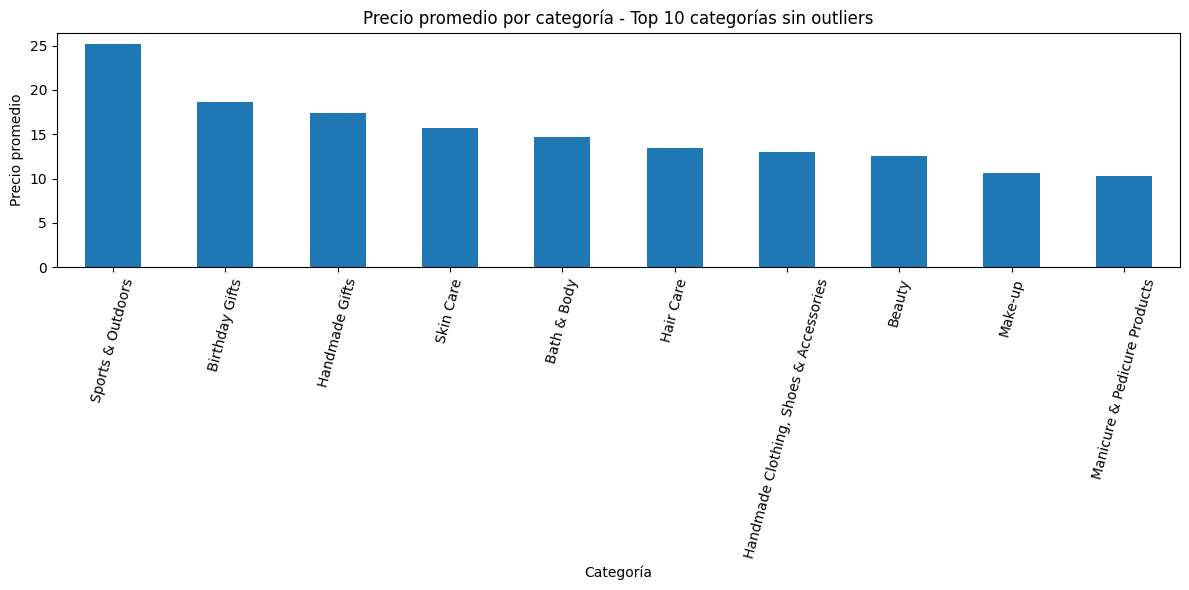

In [26]:
# gráfico de barras precio promedio
plt.figure(figsize=(12, 6))

average_price_top_10.plot(kind="bar")

plt.title("Precio promedio por categoría - Top 10 categorías sin outliers")
plt.xlabel("Categoría")
plt.ylabel("Precio promedio")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

## ¿Qué categoría tiene el precio promedio más alto?

In [27]:
average_price_by_category = (
    df_no_outliers
    .groupby(category_col)[price_col]
    .mean()
    .sort_values(ascending=False)
)

average_price_by_category.head(10)

category
Motherboards         68.772432
Boxing Shoes         67.417803
Desktop PCs          66.915562
Tablets              66.552971
Graphics Cards       65.103509
Digital Frames       60.745129
Streaming Clients    60.241803
Hockey Shoes         60.094796
Computer Cases       58.339884
Skiing Poles         57.867770
Name: price, dtype: float64

## Categoría con mayor precio promedio

La categoría con mayor precio promedio es la primera que aparece en la tabla ordenada de mayor a menor.

Sin embargo, la media puede verse afectada por precios altos incluso después de eliminar outliers, por lo que conviene comparar también con la mediana.

## Boxplots: ratings por categoría

In [29]:
# top 10 categorías para ratings
top_10_categories_rating = (
    df_no_outliers[category_col]
    .value_counts()
    .head(10)
    .index
)

df_top_10_rating = df_no_outliers[
    df_no_outliers[category_col].isin(top_10_categories_rating)
]

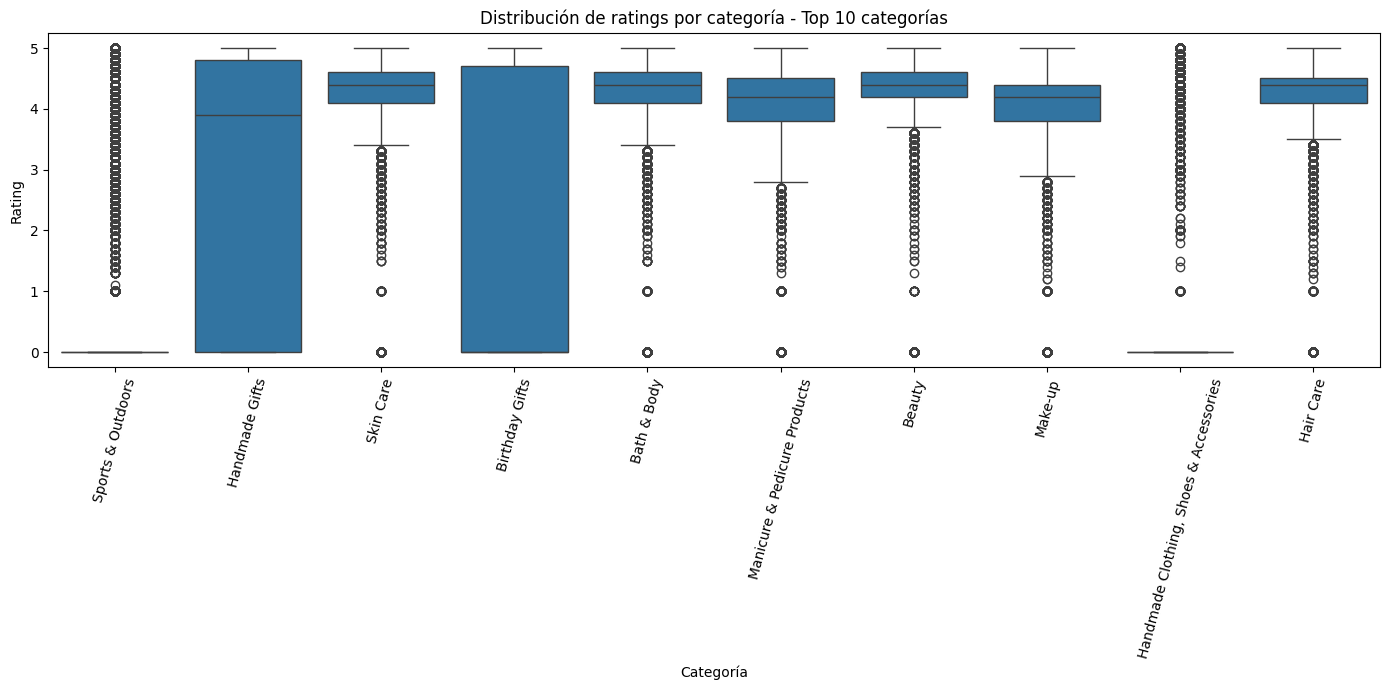

In [30]:
# boxplot rating por categoría
plt.figure(figsize=(14, 7))

sns.boxplot(
    data=df_top_10_rating,
    x=category_col,
    y=rating_col
)

plt.title("Distribución de ratings por categoría - Top 10 categorías")
plt.xlabel("Categoría")
plt.ylabel("Rating")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

## ¿Qué categoría tiene la mediana de rating más alta?

In [31]:
median_rating_by_category = (
    df_no_outliers
    .groupby(category_col)[rating_col]
    .median()
    .sort_values(ascending=False)
)

median_rating_by_category.head(10)

category
Computer Memory                 4.7
Building & Construction Toys    4.6
Office Paper Products           4.6
Luxury Food & Drink             4.6
Kids' Play Figures              4.6
Hobbies                         4.6
Beer, Wine & Spirits            4.6
Laptop Accessories              4.6
Cables & Accessories            4.5
CPUs                            4.5
Name: stars, dtype: float64

## Conclusión de negocio - Precios y ratings por categoría

El análisis muestra que las categorías no se comportan igual en términos de precio y valoración.

Algunas categorías pueden tener precios medianos o promedios más altos, lo cual puede indicar productos más premium, mayor complejidad técnica o mayor valor percibido.

Por otro lado, las categorías con ratings medianos más altos pueden reflejar una mejor satisfacción del cliente o una mayor consistencia en la calidad percibida.

Desde una perspectiva de negocio, comparar precio y rating por categoría permite identificar oportunidades de posicionamiento, diferenciación y mejora del catálogo.

# Parte 3: Relación entre precio y rating

## Pregunta de negocio

¿Existe una relación entre el precio de los productos y sus valoraciones?

En esta sección analizaremos si los productos más caros tienden a recibir mejores ratings o si precio y valoración parecen comportarse de forma independiente.

In [32]:
# correlación entre precio y rating
price_rating_data = df_no_outliers[[price_col, rating_col]].dropna()

price_rating_correlation = price_rating_data[price_col].corr(
    price_rating_data[rating_col]
)

print(f"Correlación entre precio y rating: {price_rating_correlation:.4f}")

Correlación entre precio y rating: -0.0777


## Interpretación de la correlación

La correlación mide la relación lineal entre precio y rating.

Su valor puede ir de -1 a 1:

- cercano a 1: relación positiva fuerte,
- cercano a -1: relación negativa fuerte,
- cercano a 0: relación débil o inexistente.

Si la correlación está cerca de 0, significa que el precio no explica claramente el rating del producto.

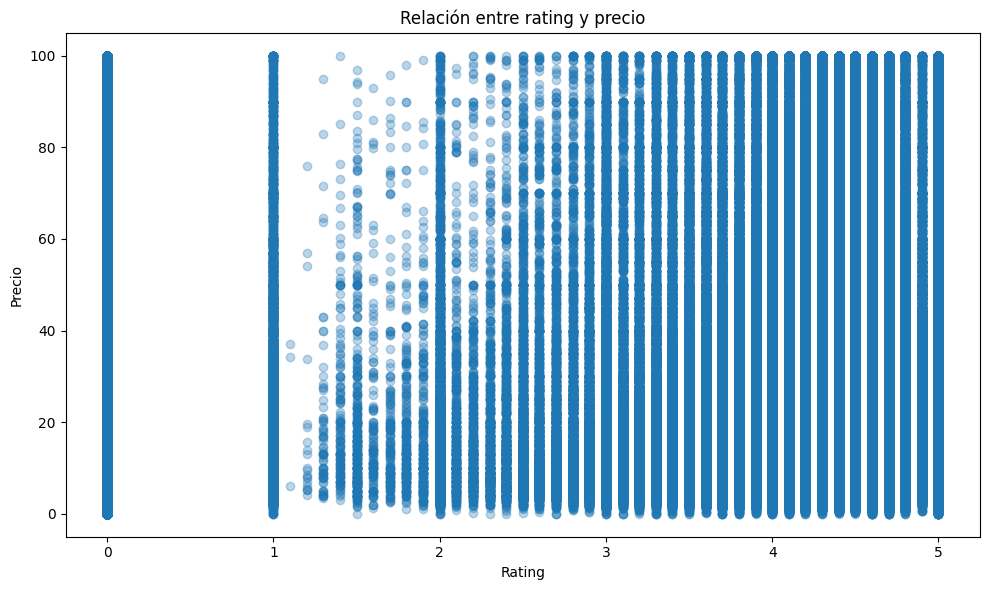

In [33]:
# scatter plot precio vs rating
plt.figure(figsize=(10, 6))

plt.scatter(
    price_rating_data[rating_col],
    price_rating_data[price_col],
    alpha=0.3
)

plt.title("Relación entre rating y precio")
plt.xlabel("Rating")
plt.ylabel("Precio")
plt.tight_layout()
plt.show()

## Interpretación del scatter plot

El scatter plot permite observar visualmente si existe una relación clara entre rating y precio.

Si los puntos forman una tendencia ascendente, podría indicar que productos con mayor rating tienden a tener precios más altos.

Si los puntos aparecen muy dispersos, sin patrón claro, esto sugiere que la relación entre precio y rating es débil.

## Heatmap de correlación

In [34]:
# seleccionar variables numéricas
numeric_df = df_no_outliers.select_dtypes(include=["number"])

numeric_df.head()

,uid,stars,reviews,price,boughtinlastmonth
0,1,4.7,15308,21.99,0
1,2,4.7,98099,23.99,0
2,3,4.7,15308,21.99,0
3,4,4.7,7205,31.99,0
4,5,4.6,1881,17.99,0


In [35]:
# matriz de correlación
correlation_matrix = numeric_df.corr()

correlation_matrix

,uid,stars,reviews,price,boughtinlastmonth
uid,1.000000,0.030288,0.020236,0.001717,0.017116
stars,0.030288,1.000000,0.083920,-0.077673,0.113994
reviews,0.020236,0.083920,1.000000,-0.008498,0.105624
price,0.001717,-0.077673,-0.008498,1.000000,-0.059051
boughtinlastmonth,0.017116,0.113994,0.105624,-0.059051,1.000000


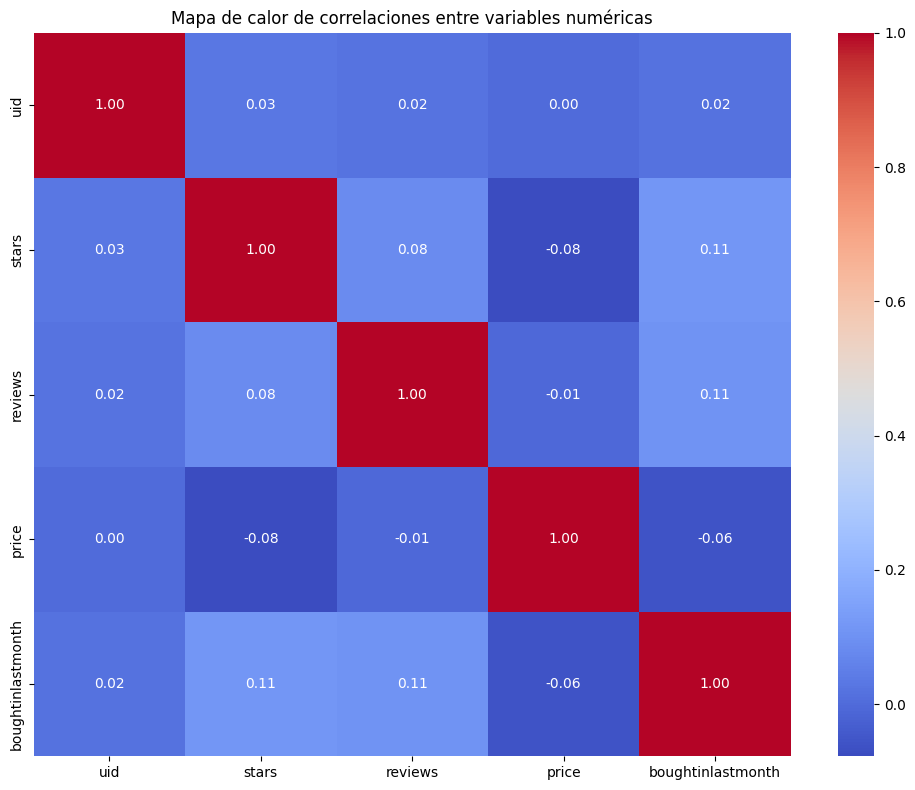

In [36]:
# heatmap
plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Mapa de calor de correlaciones entre variables numéricas")
plt.tight_layout()
plt.show()

## Interpretación del heatmap

El heatmap muestra la correlación entre todas las variables numéricas del dataset.

Los valores cercanos a 1 indican relación positiva fuerte.

Los valores cercanos a -1 indican relación negativa fuerte.

Los valores cercanos a 0 indican una relación débil o inexistente.

Este gráfico ayuda a identificar rápidamente qué variables numéricas se relacionan entre sí.

## QQ Plot: comprobar si los precios siguen una distribución normal

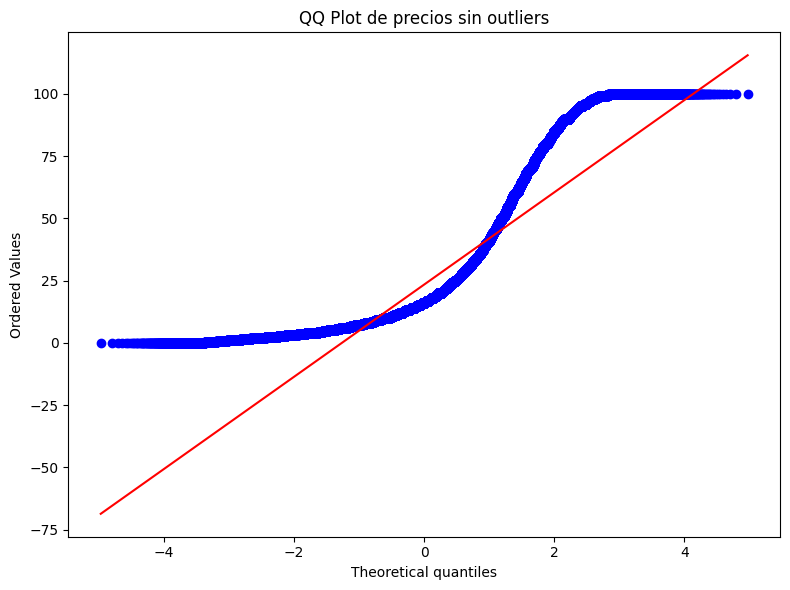

In [37]:
# QQ plot
plt.figure(figsize=(8, 6))

stats.probplot(
    df_no_outliers[price_col].dropna(),
    dist="norm",
    plot=plt
)

plt.title("QQ Plot de precios sin outliers")
plt.tight_layout()
plt.show()

## Interpretación del QQ Plot

El QQ plot permite comparar la distribución de los precios con una distribución normal.

Si los puntos siguen aproximadamente una línea recta, los precios se parecen a una distribución normal.

Si los puntos se desvían mucho de la línea, los precios no siguen una distribución normal.

En datos de precios de productos, es común que la distribución no sea perfectamente normal, porque suele haber muchos productos baratos o moderados y algunos productos más caros.

## Conclusión final de negocio

El análisis bivariado del dataset de Amazon UK permite entender mejor cómo se relacionan las categorías, los precios, los ratings y el estado de best-seller.

En primer lugar, el análisis entre categoría y best-seller permite identificar si algunas categorías concentran una mayor proporción de productos exitosos. Si el test Chi-square muestra significancia estadística, esto sugiere que el estado de best-seller no está distribuido de forma completamente independiente respecto a la categoría. Sin embargo, Cramér's V permite evaluar si esta relación es fuerte o débil desde un punto de vista práctico.

En segundo lugar, el análisis de precios por categoría muestra que algunas categorías tienden a posicionarse en rangos de precio más altos que otras. La eliminación de outliers mediante IQR ayuda a obtener visualizaciones más claras y a evitar que productos extremadamente caros distorsionen el análisis.

En tercer lugar, el análisis de ratings por categoría permite identificar qué categorías reciben mejores valoraciones medianas por parte de los clientes. Esto puede ayudar a detectar categorías con mayor satisfacción, mejor percepción de calidad o menor variabilidad en la experiencia del cliente.

Finalmente, la relación entre precio y rating permite evaluar si los productos más caros reciben mejores valoraciones. Si la correlación es débil, esto indica que el precio por sí solo no explica la satisfacción del cliente y que otras variables como marca, reviews, categoría o calidad percibida pueden tener mayor influencia.

En conjunto, este análisis ofrece una base sólida para tomar decisiones sobre estrategia de precios, posicionamiento de productos, análisis competitivo y gestión del catálogo en Amazon UK.